In [1]:
#merge two csv files 

import pandas as pd

file1="data/Jan_2019_ontime.csv"
file2="data/Jan_2020_ontime.csv"

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)
df = pd.concat([df1, df2])
df.to_csv("data/Jan_2019_2020_ontime.csv", index=False)

In [6]:
#total num of flights 

print("Total number of flights in Jan 2019 and Jan 2020:", len(df))

Total number of flights in Jan 2019 and Jan 2020: 1191331


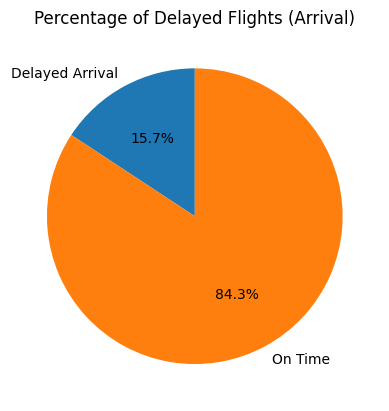

In [15]:
# percentage of delayed flights on arrival
import matplotlib.pyplot as plt

delayed = df['ARR_DEL15'].sum()
delayed_pct = delayed / len(df) * 100

plt.pie([delayed, len(df)-delayed],
        labels=['Delayed Arrival', 'On Time'],
        autopct='%1.1f%%',
        startangle=90)
plt.title("Percentage of Delayed Flights (Arrival)")
plt.show()


([<matplotlib.patches.Wedge at 0x16996a5d0>,
 [Text(-0.5048386917434617, 0.9773115651207399, 'Delayed Departure'),
  Text(0.5048387771827537, -0.9773115209863342, 'On Time')],
 [Text(-0.2753665591327973, 0.5330790355204035, '15.2%'),
  Text(0.2753666057360475, -0.5330790114470914, '84.8%')])

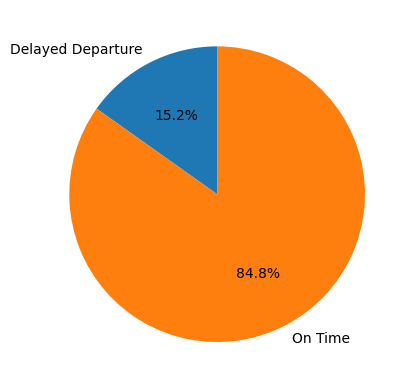

In [14]:
#percentage of delayed flights on departure
delayed_dep = df['DEP_DEL15'].sum()
delayed_dep_pct = delayed_dep / len(df) * 100
plt.pie([delayed_dep, len(df)-delayed_dep],
        labels=['Delayed Departure', 'On Time'],
        autopct='%1.1f%%',
        startangle=90)

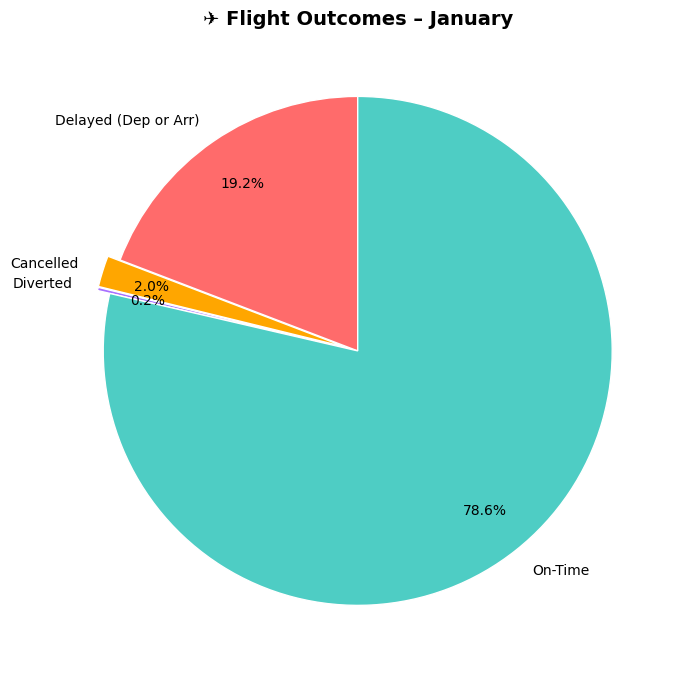

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset (make sure your df is loaded)
# df = pd.read_csv("january_flights.csv")

# Create delay flag (either departure or arrival)
df['DELAYED_EITHER'] = ((df['DEP_DEL15'] == 1) | (df['ARR_DEL15'] == 1)).astype(int)

# Define each category
cancelled = df['CANCELLED'].sum()
diverted = df['DIVERTED'].sum()
delayed = df['DELAYED_EITHER'].sum()
on_time = len(df) - (cancelled + diverted + delayed)

# Prepare data
labels = ['Delayed (Dep or Arr)', 'Cancelled', 'Diverted', 'On-Time']
sizes = [delayed, cancelled, diverted, on_time]
colors = ['#FF6B6B', '#FFA600', '#A870FF', '#4ECDC4']

# “Explode” small slices a bit to make labels clearer
explode = [0.05 if s < (0.03 * sum(sizes)) else 0 for s in sizes]

# Plot pie chart
plt.figure(figsize=(7,7))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'white'},
    pctdistance=0.8,
    labeldistance=1.1,
    explode=explode
)

plt.title("✈️ Flight Outcomes – January", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


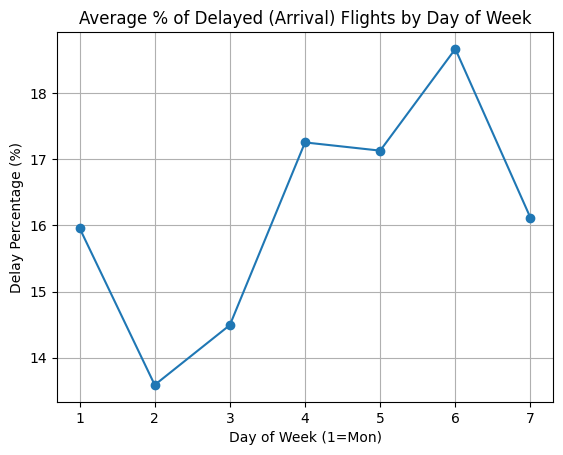

In [16]:
#avg delay for each day of the week 

delay_by_day = df.groupby('DAY_OF_WEEK')['ARR_DEL15'].mean() * 100

plt.plot(delay_by_day.index, delay_by_day.values, marker='o')
plt.title("Average % of Delayed (Arrival) Flights by Day of Week")
plt.xlabel("Day of Week (1=Mon)")
plt.ylabel("Delay Percentage (%)")
plt.grid(True)
plt.show()



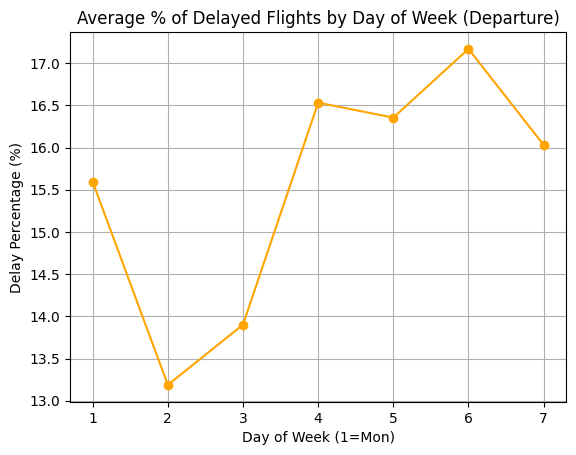

In [5]:
#avg dep delay for each day of the week
delay_by_day_dep = df.groupby('DAY_OF_WEEK')['DEP_DEL15'].mean() * 100
plt.plot(delay_by_day_dep.index, delay_by_day_dep.values, marker='o', color='orange')
plt.title("Average % of Delayed Flights by Day of Week (Departure)")
plt.xlabel("Day of Week (1=Mon)")
plt.ylabel("Delay Percentage (%)")
plt.grid(True)
plt.show()


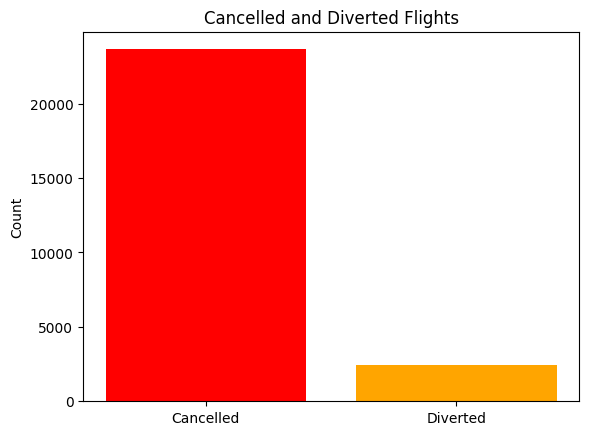

In [7]:
cancelled = df['CANCELLED'].sum()
diverted = df['DIVERTED'].sum()

plt.bar(['Cancelled', 'Diverted'], [cancelled, diverted], color=['red', 'orange'])
plt.title("Cancelled and Diverted Flights")
plt.ylabel("Count")
plt.show()


/var/folders/z8/s1r54khs3b3g5pz151jsffdr0000gn/T/ipykernel_76121/2255581778.py:37: UserWarning: Glyph 127744 (\N{CYCLONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/wbagger/Documents/cmpe481_project/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127744 (\N{CYCLONE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


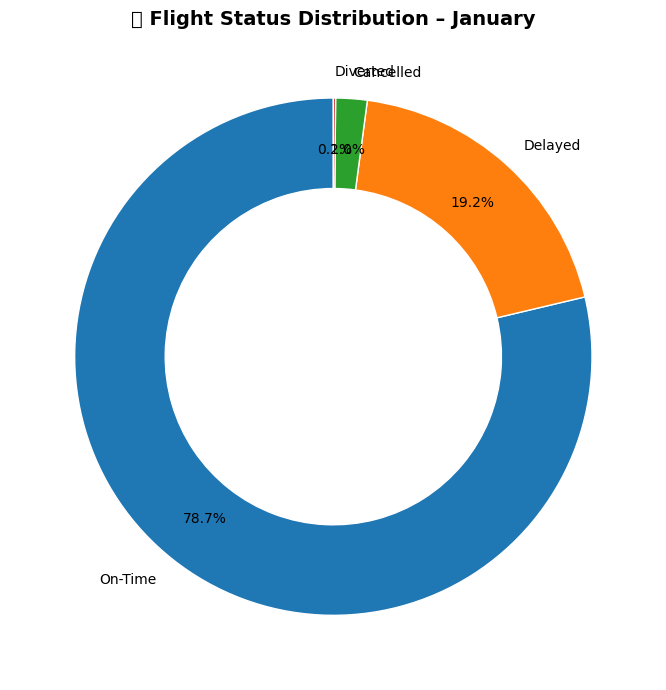

In [11]:
import pandas as pd
import matplotlib.pyplot as plt


# Categorize flights (no double counting)
conditions = [
    (df['CANCELLED'] == 1),
    (df['DIVERTED'] == 1),
    ((df['DEP_DEL15'] == 1) | (df['ARR_DEL15'] == 1))
]
choices = ['Cancelled', 'Diverted', 'Delayed']

df['Flight_Status'] = 'On-Time'
for cond, choice in zip(conditions, choices):
    df.loc[cond, 'Flight_Status'] = choice

# Count each status
status_counts = df['Flight_Status'].value_counts()

# Donut chart
fig, ax = plt.subplots(figsize=(7,7))
wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.8,
    wedgeprops={'width': 0.35, 'edgecolor': 'white'}
)

# Center circle for donut look
centre_circle = plt.Circle((0,0), 0.60, fc='white')
fig.gca().add_artist(centre_circle)

# Formatting
plt.title("🌀 Flight Status Distribution – January", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
